# Baseline Analysis
This notebook loads logged baseline runs and creates a quick comparison table and metric plots.

In [1]:
import json

import pandas as pd

import matplotlib.pyplot as plt



records = []

with open('../results/experiment_runs.jsonl', 'r', encoding='utf-8') as f:

    for line in f:

        line = line.strip()

        if line:

            records.append(json.loads(line))



runs = pd.DataFrame(records)

runs.tail()

Matplotlib is building the font cache; this may take a moment.


,run_id,model,random_seed,sample_rows,test_size,threshold_quantile,contamination,n_estimators,threshold,roc_auc,...,weight_decay,batch_size,epochs,temperature,recon_weight,contrastive_weight,final_train_loss,aug_strategy,noise_std,mask_prob
14,contrastive_ssl_20260505T170416Z,contrastive_ssl,42,30000,0.3,0.95,NaN,NaN,5.616437,0.792323,...,0.0001,256.0,100.0,0.5,0.5,0.5,2.39299,combined,0.05,0.15
15,contrastive_ssl_20260505T170447Z,contrastive_ssl,42,30000,0.3,0.95,NaN,NaN,6.005664,0.781048,...,0.0001,256.0,50.0,0.5,0.5,0.5,2.44031,combined,0.05,0.15
16,isolation_forest_20260505T170518Z,isolation_forest,42,30000,0.3,0.95,0.05,200.0,0.604684,0.755461,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17,one_class_svm_20260505T170521Z,one_class_svm,42,30000,0.3,0.95,NaN,NaN,-0.003459,0.652122,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18,contrastive_ssl_20260505T170534Z,contrastive_ssl,42,30000,0.3,0.95,NaN,NaN,5.616437,0.792323,...,0.0001,256.0,100.0,0.5,0.5,0.5,2.39299,combined,0.05,0.15


In [2]:
latest = runs.sort_values('run_id').groupby('model', as_index=False).tail(1).reset_index(drop=True)
cols = ['model', 'roc_auc', 'pr_auc', 'precision', 'recall', 'f1', 'fpr']
latest[cols]

,model,roc_auc,pr_auc,precision,recall,f1,fpr
0,contrastive_ssl,0.792323,0.930245,0.993007,0.066428,0.124525,0.001550
1,isolation_forest,0.755461,0.887901,0.936330,0.058475,0.110076,0.013178
2,one_class_svm,0.652122,0.900849,0.998819,0.065960,0.123748,0.000258


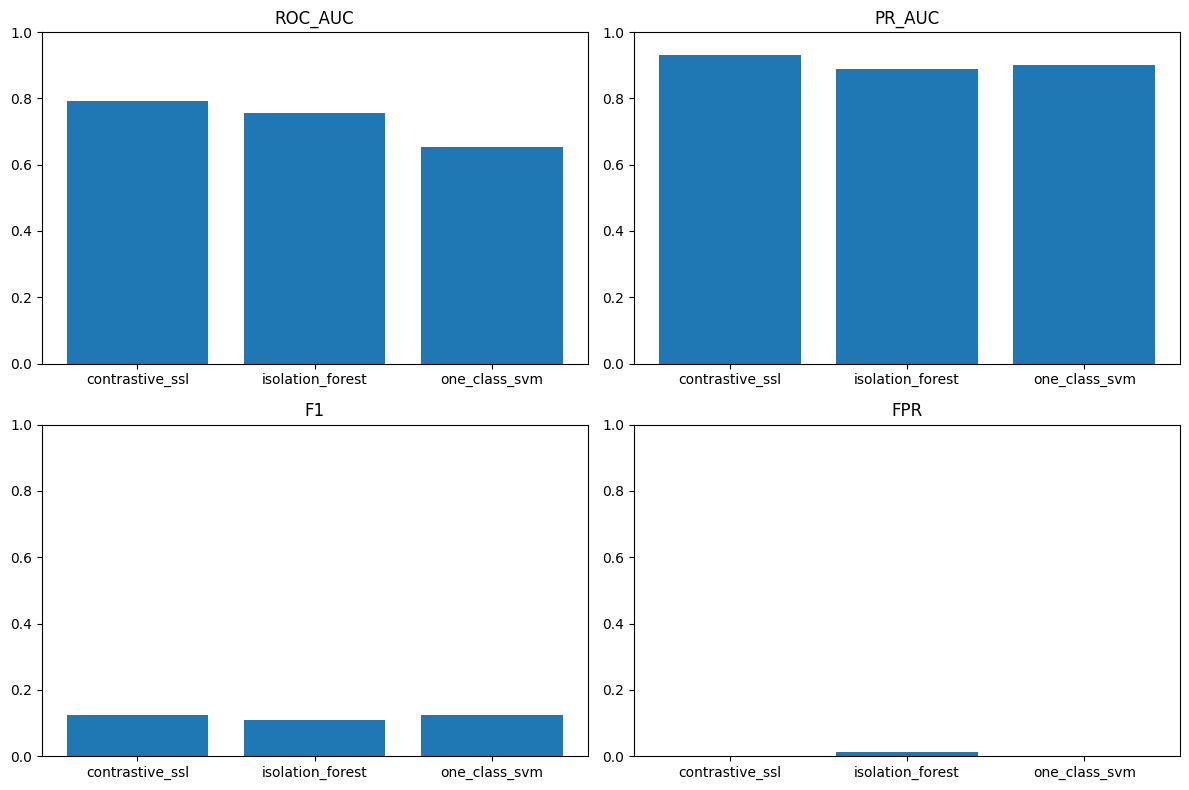

In [3]:
plot_cols = ['roc_auc', 'pr_auc', 'f1', 'fpr']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for i, metric in enumerate(plot_cols):
    axes[i].bar(latest['model'], latest[metric])
    axes[i].set_title(metric.upper())
    axes[i].set_ylim(0, 1)

plt.tight_layout()
plt.show()

## Notes
- Use this notebook to inspect baseline trade-offs before starting SSL modeling.
- Export key figures for your report and portfolio README.